# 07 · Análisis de resultados e hipótesis H1–H6
TA Aprendizaje de Máquina, grupo 5. Entregable 2.

**Objetivo.** Contrastar las hipótesis del diseño experimental con intervalos de confianza por bootstrap de días y pruebas de Wilcoxon, ablación por grupos de variables, comparación de funciones de pérdida y sensibilidad a la regla de 60 min.

Los modelos que se reajustan aquí usan los hiperparámetros elegidos por validación en el notebook 04 (nada se elige con el conjunto de prueba).

**Entradas:** `data/processed/corte_k{k}*.pkl`, `data/processed/03_pred_test.pkl`, `data/processed/04_pred_test.pkl`, `results/tables/04_hiperparametros.csv`. **Salidas:** `results/tables/07_*.csv`, `results/figures/07_*.png`.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance

RAIZ = Path("..")
sys.path.insert(0, str(RAIZ.resolve()))
from src.variables import CORTES, GRUPOS, NOMBRE_GRUPO, columnas_modelo
from src.modelos import REGRESORES, pipeline, validar_y_probar
from src.evaluacion import SEMILLA, ic_bootstrap_dias, metricas_regresion, wilcoxon_pares
from src import graficos

DIR_PROC = RAIZ / "data" / "processed"
DIR_FIG = RAIZ / "results" / "figures"
DIR_TAB = RAIZ / "results" / "tables"
warnings.filterwarnings("ignore", category=ConvergenceWarning)
graficos.estilo()

hiper = pd.read_csv(DIR_TAB / "04_hiperparametros.csv")
mejor_por_k = pd.read_csv(DIR_TAB / "04_mejor_modelo_por_k.csv").set_index("k")["modelo"]
pred = pd.concat([pd.read_pickle(DIR_PROC / "03_pred_test.pkl"), pd.read_pickle(DIR_PROC / "04_pred_test.pkl")])
pred["error_abs"] = (pred["y"] - pred["pred"]).abs()
datos = {k: pd.read_pickle(DIR_PROC / f"corte_k{k}.pkl") for k in CORTES}


def modelo_ajustado(nombre, k, **cambios):
    params = json.loads(hiper[(hiper["k"] == k) & (hiper["modelo"] == nombre)]["mejores_parametros"].item())
    return clone(REGRESORES[nombre][0]).set_params(**{**params, **cambios})


def particion(x):
    return x[x["conjunto"] == "train"].reset_index(drop=True), x[x["conjunto"] == "test"].reset_index(drop=True)


mejor_por_k

k
4     Gradient Boosting
6     Gradient Boosting
9     Gradient Boosting
12    Gradient Boosting
15    Gradient Boosting
Name: modelo, dtype: str

## 1. Intervalos de confianza por bootstrap de días (prueba)
IC del 95 % del MAE remuestreando los 7 días de prueba con reemplazo (2.000 réplicas).

In [2]:
filas = []
for (k, modelo), g in pred.groupby(["k", "modelo"]):
    lo, hi = ic_bootstrap_dias(g["error_abs"], g["fecha"])
    filas.append({"k": k, "modelo": modelo, "MAE": g["error_abs"].mean(), "IC_inf": lo, "IC_sup": hi})
ic = pd.DataFrame(filas)
ic.to_csv(DIR_TAB / "07_ic_bootstrap.csv", index=False, float_format="%.6f")
ic[ic["k"] == 9].sort_values("MAE").round(2)

,k,modelo,MAE,IC_inf,IC_sup
38,9,Gradient Boosting,2.64,2.25,3.20
42,9,Random Forest,2.70,2.27,3.31
37,9,Bagging,2.72,2.33,3.35
46,9,SVR (RBF),2.81,2.39,3.38
40,9,KNN,2.99,2.46,3.79
32,9,AdaBoost,3.01,2.60,3.68
47,9,Árbol de decisión,3.04,2.50,3.89
39,9,Huber,3.20,2.68,3.90
34,9,B1 mediana hora-día,3.20,2.66,3.96
45,9,Ridge,3.28,2.78,3.94


## 2. H1 y H3: atraso observado frente a horario y efecto del punto de corte
Mejor modelo de cada k (por MAE de validación) frente a B1 (solo horario) y B2 (persistencia). La ablación de la sección 4 aísla el aporte del atraso observado con el mismo algoritmo.

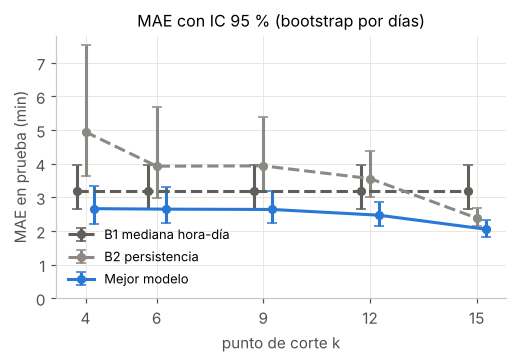

,k,modelo_a,modelo_b,MAE_a,MAE_b,p_vuelta,p_dia
0,4,Gradient Boosting,B1 mediana hora-día,2.6626,3.2008,0.0,0.0156
1,4,Gradient Boosting,B2 persistencia,2.6626,4.9434,0.0,0.0156
0,6,Gradient Boosting,B1 mediana hora-día,2.6482,3.2008,0.0,0.0156
1,6,Gradient Boosting,B2 persistencia,2.6482,3.9255,0.0,0.0156
0,9,Gradient Boosting,B1 mediana hora-día,2.6388,3.2008,0.0,0.0156
1,9,Gradient Boosting,B2 persistencia,2.6388,3.9350,0.0,0.0156
0,12,Gradient Boosting,B1 mediana hora-día,2.4684,3.2008,0.0,0.0156
1,12,Gradient Boosting,B2 persistencia,2.4684,3.5580,0.0,0.0156
0,15,Gradient Boosting,B1 mediana hora-día,2.0532,3.2008,0.0,0.0156
1,15,Gradient Boosting,B2 persistencia,2.0532,2.3836,0.0,0.0156


In [3]:
sel = []
for k in CORTES:
    for nombre in ["B1 mediana hora-día", "B2 persistencia", mejor_por_k[k]]:
        fila = ic[(ic["k"] == k) & (ic["modelo"] == nombre)].iloc[0].to_dict()
        fila["serie"] = "Mejor modelo" if nombre == mejor_por_k[k] else nombre
        sel.append(fila)
sel = pd.DataFrame(sel)
fig, ax = plt.subplots(figsize=(4.8, 3.4))
colores = {"B1 mediana hora-día": graficos.COLOR_MODELO["B1 mediana hora-día"],
           "B2 persistencia": graficos.COLOR_MODELO["B2 persistencia"], "Mejor modelo": graficos.PALETA[0]}
for i, (serie, d) in enumerate(sel.groupby("serie", sort=False)):
    desp = (i - 1) * 0.25
    ax.errorbar(d["k"] + desp, d["MAE"], yerr=[d["MAE"] - d["IC_inf"], d["IC_sup"] - d["MAE"]], marker="o",
                capsize=3, linewidth=2, linestyle="--" if serie.startswith("B") else "-", color=colores[serie], label=serie)
ax.set(xlabel="punto de corte k", ylabel="MAE en prueba (min)", xticks=CORTES, ylim=(0, None),
       title="MAE con IC 95 % (bootstrap por días)")
ax.legend(loc="lower left")
graficos.guardar(fig, DIR_FIG / "07_mae_vs_k_ic.png")

errores_vs_base = []
for k in CORTES:
    p = pred[pred["k"] == k].pivot(index="id", columns="modelo", values="error_abs")
    dias = pred[(pred["k"] == k) & (pred["modelo"] == "B0 a tiempo")].set_index("id").loc[p.index, "fecha"]
    w = wilcoxon_pares({m: p[m] for m in [mejor_por_k[k], "B1 mediana hora-día", "B2 persistencia"]}, dias)
    errores_vs_base.append(w[w["modelo_a"] == mejor_por_k[k]].assign(k=k))
wil_base = pd.concat(errores_vs_base)[["k", "modelo_a", "modelo_b", "MAE_a", "MAE_b", "p_vuelta", "p_dia"]]
wil_base.to_csv(DIR_TAB / "07_wilcoxon_mejor_vs_base.csv", index=False, float_format="%.6f")
wil_base.round(4)

## 3. H2: modelos lineales frente a árboles
Ridge frente a Random Forest y Gradient Boosting en cada k (Wilcoxon emparejado por vuelta y por MAE diario).

In [4]:
h2 = []
for k in CORTES:
    p = pred[pred["k"] == k].pivot(index="id", columns="modelo", values="error_abs")
    dias = pred[(pred["k"] == k) & (pred["modelo"] == "B0 a tiempo")].set_index("id").loc[p.index, "fecha"]
    h2.append(wilcoxon_pares({m: p[m] for m in ["Ridge", "Random Forest", "Gradient Boosting"]}, dias).assign(k=k))
h2 = pd.concat(h2)[["k", "modelo_a", "modelo_b", "MAE_a", "MAE_b", "p_vuelta", "p_dia"]]
h2.to_csv(DIR_TAB / "07_h2_wilcoxon.csv", index=False, float_format="%.6f")
h2.round(4)

,k,modelo_a,modelo_b,MAE_a,MAE_b,p_vuelta,p_dia
0,4,Ridge,Random Forest,3.9135,2.7746,0.0000,0.0156
1,4,Ridge,Gradient Boosting,3.9135,2.6626,0.0000,0.0156
2,4,Random Forest,Gradient Boosting,2.7746,2.6626,0.0002,0.0156
0,6,Ridge,Random Forest,3.2967,2.7368,0.0000,0.0156
1,6,Ridge,Gradient Boosting,3.2967,2.6482,0.0000,0.0156
2,6,Random Forest,Gradient Boosting,2.7368,2.6482,0.0019,0.0781
0,9,Ridge,Random Forest,3.2817,2.6976,0.0000,0.0156
1,9,Ridge,Gradient Boosting,3.2817,2.6388,0.0000,0.0156
2,9,Random Forest,Gradient Boosting,2.6976,2.6388,0.1202,0.3750
0,12,Ridge,Random Forest,3.0194,2.4912,0.0000,0.0156


## 4. H1, H4 y H6: ablación por grupos de variables
Mismo algoritmo e hiperparámetros, cambiando solo los grupos de variables. Se usa Gradient Boosting (mejor familia en validación) y Ridge como referencia lineal.

In [5]:
CONFIGS = {
    "Horario": ("hor",),
    "+ Atraso": ("hor", "atr"),
    "+ Vehículo/flota": ("hor", "atr", "ctx"),
    "+ GPS (completo)": ("hor", "atr", "ctx", "gps"),
    "Completo sin vehículo/flota": ("hor", "atr", "gps"),
}
ablacion, pred_abl = [], []
for k in CORTES:
    tr, te = particion(datos[k])
    for nombre in ["Gradient Boosting", "Ridge"]:
        for config, grupos in CONFIGS.items():
            cols = columnas_modelo(datos[k], grupos)
            mae_val, p = validar_y_probar(pipeline(cols, modelo_ajustado(nombre, k)), cols, tr, te)
            ablacion.append({"k": k, "modelo": nombre, "variables": config, "MAE_val": mae_val,
                             **metricas_regresion(te["y"], p)})
            pred_abl.append(te[["id", "fecha", "franja", "dia_semana", "y"]].assign(k=k, modelo=nombre, variables=config, pred=p))
ablacion = pd.DataFrame(ablacion)
pred_abl = pd.concat(pred_abl, ignore_index=True)
pred_abl["error_abs"] = (pred_abl["y"] - pred_abl["pred"]).abs()
ablacion.to_csv(DIR_TAB / "07_ablacion.csv", index=False, float_format="%.6f")
ablacion.pivot_table(index=["modelo", "variables"], columns="k", values="MAE", sort=False).round(2)

k                                                4     6     9     12    15
modelo            variables                                                
Gradient Boosting Horario                      2.78  2.88  2.91  2.85  2.73
                  + Atraso                     2.75  2.71  2.72  2.50  2.10
                  + Vehículo/flota             2.67  2.63  2.62  2.47  2.05
                  + GPS (completo)             2.66  2.65  2.64  2.47  2.05
                  Completo sin vehículo/flota  2.75  2.68  2.72  2.49  2.11
Ridge             Horario                      3.97  4.01  4.35  4.52  4.02
                  + Atraso                     3.74  3.33  3.26  2.91  2.31
                  + Vehículo/flota             3.90  3.31  3.30  3.01  2.27
                  + GPS (completo)             3.91  3.30  3.28  3.02  2.29
                  Completo sin vehículo/flota  3.73  3.33  3.26  2.92  2.32

In [6]:
ablacion.pivot_table(index=["modelo", "variables"], columns="k", values="MAE_val", sort=False).round(2)

k                                                4     6     9     12    15
modelo            variables                                                
Gradient Boosting Horario                      3.13  3.13  3.12  3.11  3.13
                  + Atraso                     3.13  3.09  3.03  2.84  2.46
                  + Vehículo/flota             3.08  3.04  2.98  2.78  2.41
                  + GPS (completo)             3.09  3.04  2.98  2.77  2.38
                  Completo sin vehículo/flota  3.12  3.08  3.01  2.82  2.43
Ridge             Horario                      4.28  4.34  4.35  4.35  4.43
                  + Atraso                     3.93  3.64  3.55  3.23  2.62
                  + Vehículo/flota             3.85  3.50  3.45  3.13  2.56
                  + GPS (completo)             3.85  3.50  3.44  3.13  2.52
                  Completo sin vehículo/flota  3.92  3.64  3.53  3.22  2.57

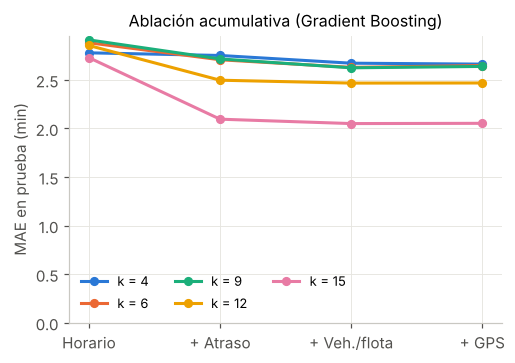

In [7]:
gb = ablacion[(ablacion["modelo"] == "Gradient Boosting") & (ablacion["variables"] != "Completo sin vehículo/flota")]
fig, ax = plt.subplots(figsize=(4.8, 3.4))
etiquetas = list(CONFIGS)[:4]
for i, k in enumerate(CORTES):
    d = gb[gb["k"] == k].set_index("variables").loc[etiquetas]
    ax.plot(range(4), d["MAE"], marker="o", color=graficos.PALETA[i], label=f"k = {k}")
ax.set(xticks=range(4), xticklabels=["Horario", "+ Atraso", "+ Veh./flota", "+ GPS"], ylabel="MAE en prueba (min)", ylim=(0, None),
       title="Ablación acumulativa (Gradient Boosting)")
ax.legend(loc="lower left", ncol=3)
graficos.guardar(fig, DIR_FIG / "07_ablacion.png")

Prueba de Wilcoxon de cada paso de la ablación (Gradient Boosting): ¿el grupo agregado reduce el error de forma significativa?

In [8]:
pasos = []
for k in CORTES:
    d = pred_abl[(pred_abl["k"] == k) & (pred_abl["modelo"] == "Gradient Boosting")]
    p = d.pivot(index="id", columns="variables", values="error_abs")
    dias = d.drop_duplicates("id").set_index("id").loc[p.index, "fecha"]
    for a, b in [("Horario", "+ Atraso"), ("+ Atraso", "+ Vehículo/flota"), ("+ Vehículo/flota", "+ GPS (completo)"),
                 ("Completo sin vehículo/flota", "+ GPS (completo)")]:
        w = wilcoxon_pares({a: p[a], b: p[b]}, dias).iloc[0]
        pasos.append({"k": k, "sin": a, "con": b, "MAE_sin": w["MAE_a"], "MAE_con": w["MAE_b"],
                      "p_vuelta": w["p_vuelta"], "p_dia": w["p_dia"]})
pasos = pd.DataFrame(pasos)
pasos.to_csv(DIR_TAB / "07_ablacion_wilcoxon.csv", index=False, float_format="%.6f")
pasos.round(4)

,k,sin,con,MAE_sin,MAE_con,p_vuelta,p_dia
0,4,Horario,+ Atraso,2.7788,2.7516,0.0889,0.4688
1,4,+ Atraso,+ Vehículo/flota,2.7516,2.6721,0.0007,0.2969
2,4,+ Vehículo/flota,+ GPS (completo),2.6721,2.6626,0.2971,0.3750
3,4,Completo sin vehículo/flota,+ GPS (completo),2.7487,2.6626,0.0002,0.3750
4,6,Horario,+ Atraso,2.8826,2.7075,0.0000,0.0781
5,6,+ Atraso,+ Vehículo/flota,2.7075,2.6292,0.0035,0.2188
6,6,+ Vehículo/flota,+ GPS (completo),2.6292,2.6482,0.0452,0.0469
7,6,Completo sin vehículo/flota,+ GPS (completo),2.6756,2.6482,0.1068,0.3750
8,9,Horario,+ Atraso,2.9119,2.7160,0.0000,0.0312
9,9,+ Atraso,+ Vehículo/flota,2.7160,2.6244,0.0009,0.0781


H6: error por franja horaria y día con y sin el grupo de vehículo y flota (Gradient Boosting, k = 9).

In [9]:
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
d9 = pred_abl[(pred_abl["k"] == 9) & (pred_abl["modelo"] == "Gradient Boosting")
              & pred_abl["variables"].isin(["+ Atraso", "+ Vehículo/flota"])]
h6_franja = d9.pivot_table(index="franja", columns="variables", values="error_abs", aggfunc="mean")[["+ Atraso", "+ Vehículo/flota"]]
h6_franja["n"] = d9[d9["variables"] == "+ Atraso"].groupby("franja").size()
h6_franja["mejora_min"] = h6_franja["+ Atraso"] - h6_franja["+ Vehículo/flota"]
h6_dia = d9.pivot_table(index="dia_semana", columns="variables", values="error_abs", aggfunc="mean")[["+ Atraso", "+ Vehículo/flota"]]
h6_dia["n"] = d9[d9["variables"] == "+ Atraso"].groupby("dia_semana").size()
h6_dia["mejora_min"] = h6_dia["+ Atraso"] - h6_dia["+ Vehículo/flota"]
h6_dia.index = [DIAS[i] for i in h6_dia.index]
h6 = pd.concat({"franja": h6_franja, "día": h6_dia})
h6.to_csv(DIR_TAB / "07_h6_franja_dia.csv", float_format="%.6f")
h6.round(2)

variables       + Atraso  + Vehículo/flota    n  mejora_min
franja 04-07 h      2.11              1.98  181        0.13
       07-10 h      2.30              2.32  215       -0.02
       10-13 h      2.22              2.09  219        0.14
       13-16 h      2.94              2.91  220        0.02
       16-19 h      3.93              3.61  190        0.32
       19-22 h      3.49              4.00   36       -0.51
día    lun          2.96              2.85  168        0.11
       mar          2.21              2.20  161        0.01
       mié          2.22              2.17  171        0.05
       jue          2.17              2.07  179        0.10
       vie          2.76              2.65  174        0.11
       sáb          4.97              4.63  107        0.34
       dom          2.47              2.52  101       -0.05

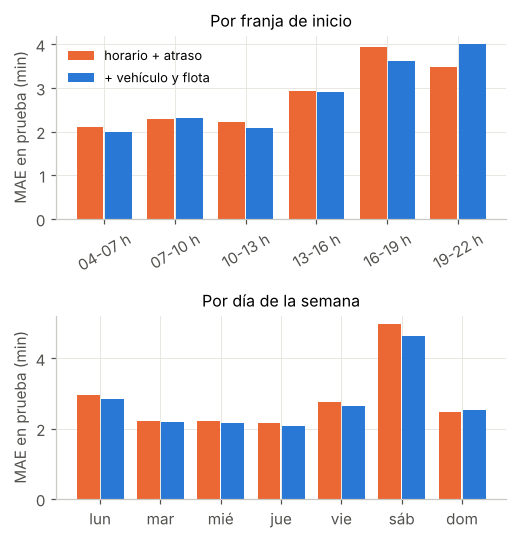

In [10]:
fig, ejes = plt.subplots(2, 1, figsize=(4.8, 5))
for ax, tabla, titulo in [(ejes[0], h6_franja, "Por franja de inicio"), (ejes[1], h6_dia, "Por día de la semana")]:
    xs = np.arange(len(tabla))
    ax.bar(xs - 0.2, tabla["+ Atraso"], width=0.38, color=graficos.PALETA[1], label="horario + atraso")
    ax.bar(xs + 0.2, tabla["+ Vehículo/flota"], width=0.38, color=graficos.PALETA[0], label="+ vehículo y flota")
    ax.set(xticks=xs, title=titulo)
    ax.set_xticklabels(tabla.index, rotation=30 if titulo.startswith("Por franja") else 0)
for ax in ejes:
    ax.set_ylabel("MAE en prueba (min)")
ejes[0].legend(loc="upper left")
graficos.guardar(fig, DIR_FIG / "07_h6_franja_dia.png")

## 5. H5: funciones de pérdida
Gradient Boosting con pérdida cuadrática, absoluta y de Huber (resto de hiperparámetros fijos) y regresión lineal por mínimos cuadrados frente a regresión de Huber.

In [11]:
h5 = []
for k in CORTES:
    tr, te = particion(datos[k])
    cols = columnas_modelo(datos[k])
    variantes = {
        ("Gradient Boosting", "cuadrática"): modelo_ajustado("Gradient Boosting", k, loss="squared_error"),
        ("Gradient Boosting", "absoluta"): modelo_ajustado("Gradient Boosting", k, loss="absolute_error"),
        ("Gradient Boosting", "Huber"): modelo_ajustado("Gradient Boosting", k, loss="huber"),
        ("Lineal", "cuadrática"): modelo_ajustado("Regresión lineal", k),
        ("Lineal", "Huber"): modelo_ajustado("Huber", k),
    }
    for (familia, perdida), m in variantes.items():
        mae_val, p = validar_y_probar(pipeline(cols, m), cols, tr, te)
        h5.append({"k": k, "familia": familia, "pérdida": perdida, "MAE_val": mae_val, **metricas_regresion(te["y"], p)})
h5 = pd.DataFrame(h5)
h5.to_csv(DIR_TAB / "07_h5_perdidas.csv", index=False, float_format="%.6f")
h5.pivot_table(index=["familia", "pérdida"], columns="k", values=["MAE", "RMSE"], sort=False).round(2)

MAE                           RMSE         \
k                               4     6     9     12    15     4      6    
familia           pérdida                                                  
Gradient Boosting cuadrática  2.66  2.65  2.64  2.47  2.05   3.95   3.92   
                  absoluta    2.61  2.62  2.57  2.37  1.99   3.95   3.93   
                  Huber       2.64  2.62  2.58  2.39  2.01   3.94   3.92   
Lineal            cuadrática  4.98  3.96  3.38  3.04  2.32  13.88  10.80   
                  Huber       3.72  3.23  3.20  2.99  2.20   9.01   4.75   

                                                
k                               9     12    15  
familia           pérdida                       
Gradient Boosting cuadrática  3.86  3.61  3.08  
                  absoluta    3.82  3.50  3.01  
                  Huber       3.83  3.49  3.01  
Lineal            cuadrática  5.94  4.19  3.29  
                  Huber       4.48  4.26  3.16

## 6. Sensibilidad a la regla de 60 min
Se entrena con y sin la regla y se evalúa en dos conjuntos de prueba: todas las vueltas con punto 18 válido y solo las que no superan 60 min. En ambos casos las predictoras de prueba son las del dataset sin regla (los puntos intermedios extremos no se anulan).

In [12]:
sens = []
for k in CORTES:
    con_tr, _ = particion(datos[k])
    sin = pd.read_pickle(DIR_PROC / f"corte_k{k}_sin_regla.pkl")
    sin_tr, sin_te = particion(sin)
    extremo = sin_te["y"].abs() > 60
    for regla, tr in [("con regla", con_tr), ("sin regla", sin_tr)]:
        for nombre in ["Gradient Boosting", "Ridge"]:
            cols = columnas_modelo(sin)
            m = pipeline(cols, modelo_ajustado(nombre, k)).fit(tr[cols], tr["y"])
            p = m.predict(sin_te[cols])
            for evaluado, mask in [("todas las vueltas", np.ones(len(sin_te), bool)), ("sin |y| > 60", ~extremo.to_numpy())]:
                sens.append({"k": k, "entrenamiento": regla, "modelo": nombre, "prueba": evaluado,
                             "n": int(mask.sum()), "MAE": np.mean(np.abs(p[mask] - sin_te["y"].to_numpy()[mask])),
                             "RMSE": np.sqrt(np.mean((p[mask] - sin_te["y"].to_numpy()[mask]) ** 2))})
sens = pd.DataFrame(sens)
sens.to_csv(DIR_TAB / "07_sensibilidad_60min.csv", index=False, float_format="%.6f")
sens.pivot_table(index=["modelo", "entrenamiento", "prueba"], columns="k", values="MAE", sort=False).round(2)

k                                                     4      6      9      12  \
modelo            entrenamiento prueba                                          
Gradient Boosting con regla     todas las vueltas   7.23   7.22   7.20   7.03   
                                sin |y| > 60        2.66   2.65   2.63   2.46   
                  sin regla     todas las vueltas  11.35  10.99  10.98   6.44   
                                sin |y| > 60        9.11   8.64   8.64   4.55   
Ridge             con regla     todas las vueltas   8.77   8.66   8.34   6.85   
                                sin |y| > 60        4.15   4.13   3.79   3.18   
                  sin regla     todas las vueltas  20.89  18.89  20.39  12.44   
                                sin |y| > 60       17.44  15.47  17.03   9.94   

k                                                     15  
modelo            entrenamiento prueba                    
Gradient Boosting con regla     todas las vueltas   6.59  
                                sin |y| > 60        2.05  
                  sin regla     todas las vueltas   5.40  
                                sin |y| > 60        3.51  
Ridge             con regla     todas las vueltas   4.83  
                                sin |y| > 60        2.31  
                  sin regla     todas las vueltas  10.65  
                                sin |y| > 60        9.12

## 7. Importancia de variables por permutación (mejor modelo, k = 9)
Pérdida de MAE en prueba al permutar cada variable (10 repeticiones). Se reporta también la permutación conjunta de cada grupo.

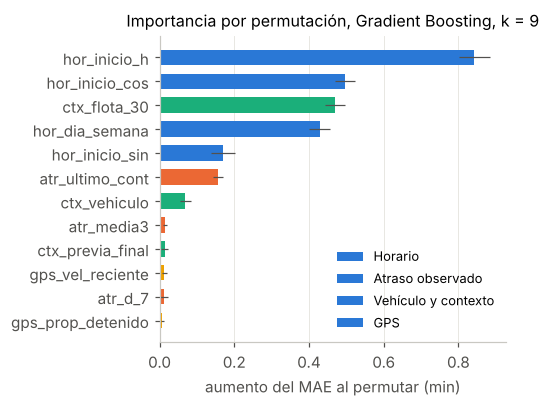

,grupo,aumento_MAE,desv
0,Horario,2.281,0.085
1,Atraso observado,0.719,0.039
2,Vehículo y contexto,0.644,0.020
3,GPS,-0.004,0.008


In [13]:
tr, te = particion(datos[9])
cols = columnas_modelo(datos[9])
nombre9 = mejor_por_k[9]
m9 = pipeline(cols, modelo_ajustado(nombre9, 9)).fit(tr[cols], tr["y"])
imp = permutation_importance(m9, te[cols], te["y"], scoring="neg_mean_absolute_error", n_repeats=10,
                             random_state=SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"variable": cols, "aumento_MAE": imp.importances_mean, "desv": imp.importances_std})
importancia = importancia.sort_values("aumento_MAE", ascending=False)
importancia.to_csv(DIR_TAB / "07_importancia_k9.csv", index=False, float_format="%.6f")

rng = np.random.default_rng(SEMILLA)
base_mae = np.mean(np.abs(m9.predict(te[cols]) - te["y"]))
por_grupo = []
for g in GRUPOS:
    cg = columnas_modelo(datos[9], (g,))
    aumentos = []
    for _ in range(10):
        xp = te[cols].copy()
        perm = rng.permutation(len(xp))
        xp[cg] = xp[cg].to_numpy()[perm]
        aumentos.append(np.mean(np.abs(m9.predict(xp) - te["y"])) - base_mae)
    por_grupo.append({"grupo": NOMBRE_GRUPO[g], "aumento_MAE": np.mean(aumentos), "desv": np.std(aumentos)})
por_grupo = pd.DataFrame(por_grupo)
por_grupo.to_csv(DIR_TAB / "07_importancia_grupos_k9.csv", index=False, float_format="%.6f")

top = importancia.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(4.8, 3.8))
color_grupo = {g: graficos.PALETA[i] for i, g in enumerate(GRUPOS)}
ax.barh(top["variable"], top["aumento_MAE"], xerr=top["desv"], color=[color_grupo[v.split("_")[0]] for v in top["variable"]],
        height=0.65, error_kw={"ecolor": graficos.TEXTO_SEC, "elinewidth": 0.8})
for g in GRUPOS:
    ax.barh([], [], color=color_grupo[g], label=NOMBRE_GRUPO[g])
ax.legend(loc="lower right")
ax.set(xlabel="aumento del MAE al permutar (min)", title=f"Importancia por permutación, {nombre9}, k = 9")
ax.grid(axis="y", visible=False)
graficos.guardar(fig, DIR_FIG / "07_importancia_k9.png")
por_grupo.round(3)

## 8. Resumen de hipótesis
| Hipótesis | Resultado | Evidencia principal |
|---|---|---|
| H1 atraso observado > solo horario | Se cumple desde k = 6 | GB solo horario 2,88–2,91 vs. + atraso 2,71–2,72 (k = 6, 9; p < 0,001); en k = 4 no es significativo |
| H2 árboles > lineales | Se cumple | GB y RF superan a Ridge en todos los k (p < 0,001 por vuelta; p ≤ 0,031 con el MAE diario) |
| H3 el error baja con k | Se cumple, no lineal | GB 2,66 → 2,64 (k = 4 a 9) y 2,47 → 2,05 (k = 12, 15) |
| H4 el GPS aporta | No se cumple | + GPS no reduce el MAE en ningún k; su importancia por permutación es ≈ 0 |
| H5 pérdidas robustas | Se cumple con matices | GB absoluta 2,57 vs. cuadrática 2,64 (k = 9); lineal Huber 3,20 vs. MCO 3,38 y RMSE 4,48 vs. 5,94 |
| H6 vehículo y flota en horas de atraso | Se cumple parcialmente | Mejora de 0,09 min global (k = 9) y de 0,32 min en 16–19 h y 0,34 min el sábado |

Sensibilidad: entrenar sin la regla de 60 min dispara el MAE (GB 8,64 vs. 2,63 en vueltas sin extremos, k = 9), así que la regla se mantiene. Las 11 vueltas extremas de prueba no son predecibles con ningún modelo y elevan el MAE a ≈ 7 min cuando se incluyen.

In [14]:
import platform, sklearn, scipy
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1
